<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS10/JS10_LAB4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import zipfile

print("Ukuran file:", os.path.getsize('images.zip') / (1024**2), "MB")
print("ZIP valid:", zipfile.is_zipfile('images.zip'))

Ukuran file: 27.50882053375244 MB
ZIP valid: True


In [3]:
import zipfile

with zipfile.ZipFile('images.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [4]:
!ls images

test  training


In [5]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [6]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))

    return img_list

train_dir = "images/training/"
test_dir = "images/test/"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

In [7]:
print("Jumlah gambar training:", len(train_img))
print("Jumlah gambar testing:", len(test_img))

Jumlah gambar training: 240
Jumlah gambar testing: 160


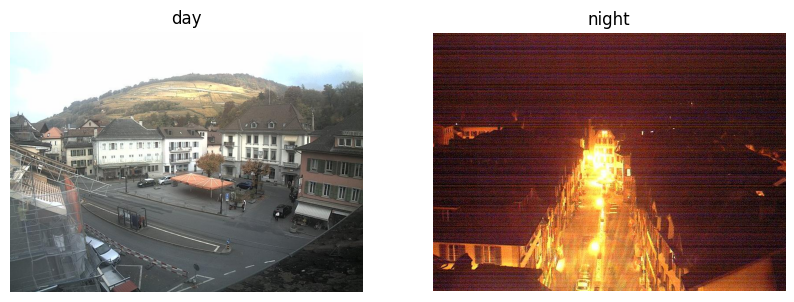

In [8]:
plt.figure(figsize=(10, 4))

for i, label in enumerate(['day', 'night']):
    img = next(img for img, lbl in train_img if lbl == label)
    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(label)
    plt.axis('off')

plt.show()

In [9]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []

    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))

    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

In [10]:
def extract_hog(X_imgs):
    feats = []

    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )

        feats.append(hog_feat)

    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

In [11]:
print("Training features:", X_train_feat.shape)
print("Testing features:", X_test_feat.shape)

Training features: (240, 34596)
Testing features: (160, 34596)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

In [14]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 0.8021 - loss: 0.9305 - val_accuracy: 0.9583 - val_loss: 0.2521
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - accuracy: 0.9740 - loss: 0.1064 - val_accuracy: 1.0000 - val_loss: 7.8020e-05
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 8.4229e-06
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 1.0000 - loss: 1.5616e-05 - val_accuracy: 1.0000 - val_loss: 1.6216e-05
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 1.0000 - loss: 1.4970e-05 - val_accuracy: 1.0000 - val_loss: 2.6164e-05
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 1.0000 - loss: 1.4615e-05 - val_accuracy: 1.0000 - val_loss: 3.4548e-05
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 1.0000 - loss: 2.3187e-05 - val_accuracy: 1.0000 - val_loss: 4.0225e-05
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 1.0000 - loss: 2.4

In [16]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)

print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9187 - loss: 0.3202
Akurasi Test: 0.918749988079071


In [17]:
print(f"Akurasi Test: {test_acc * 100:.2f}%")

Akurasi Test: 91.87%


In [18]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
              precision    recall  f1-score   support

           0       0.96      0.88      0.92        80
           1       0.89      0.96      0.92        80

    accuracy                           0.92       160
   macro avg       0.92      0.92      0.92       160
weighted avg       0.92      0.92      0.92       160

[[70 10]
 [ 3 77]]


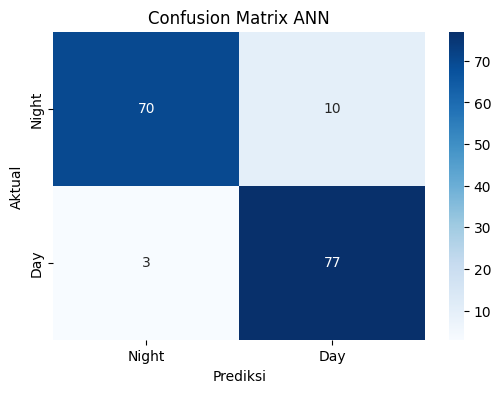

In [19]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Night', 'Day'],
    yticklabels=['Night', 'Day']
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix ANN')
plt.show()

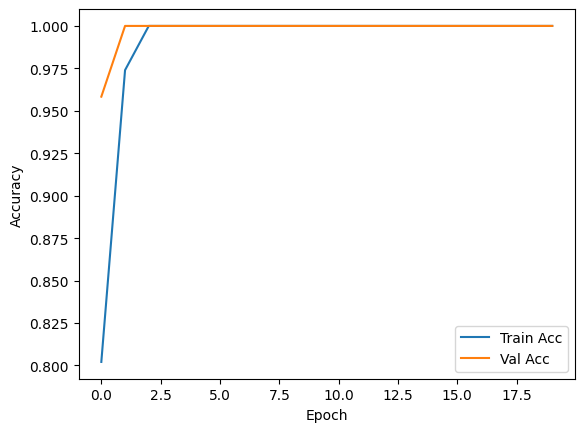

In [20]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Berdasarkan grafik hasil training, akurasi training dan validasi mengalami peningkatan pada awal epoch hingga mencapai 100%. Setelah mencapai nilai tersebut, kedua akurasi tetap stabil sampai akhir pelatihan. Hal ini menunjukkan bahwa model ANN bisa mempelajari fitur HOG untuk membedakan gambar siang dan malam dengan baik. Selain itu, tidak terdapat perbedaan yang signifikan antara akurasi training dan validasi sehingga belum terlihat adanya indikasi overfitting pada grafik tersebut. Namun, pengujian menggunakan data testing tetap diperlukan untuk mengetahui kemampuan model dalam mengklasifikasikan gambar baru.

In [21]:
model.save('day_night_classifier_model.h5')

In [22]:
import os

print(os.path.exists('day_night_classifier_model.h5'))

True


In [23]:
from google.colab import files

files.download('day_night_classifier_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>